# Evolutionary learner: evolving the weights

## Preprocessing

In [1]:
import numpy as np
import polars as pl
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
FEATURES = [
    "length", "diameter", "height", "whole_weight", "shucked_weight", "viscera_weight", "shell_weight",
    "is_infant", "is_female",
]

# cleaning and sex encoding (fixed rules, before the split)
df = pl.read_csv("./data/abalone.csv.zst")
df = df.filter(~((pl.col("height") == 0) | (pl.col("height") > 0.3)))
df = df.with_columns(
    is_infant=(pl.col("sex") == "I").cast(pl.Int8),
    is_female=(pl.col("sex") == "F").cast(pl.Int8),
).drop("sex")

# 20% hold-out test (not used until the end) and 5 stratified folds on the development part
rings_all = df["rings"].to_numpy()
y_bins = np.digitize(rings_all, np.quantile(rings_all, [0.2, 0.4, 0.6, 0.8]))
dev_idx, test_idx = train_test_split(np.arange(df.height), test_size=0.2, random_state=SEED, stratify=y_bins)
dev, test = df[dev_idx], df[test_idx]
X, rings = dev.select(FEATURES).to_numpy(), dev["rings"].to_numpy()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y_bins[dev_idx]))


def cross_validate(fit_predict, verbose=True):
    """fit_predict(X_train, y_train, X_val) -> predictions. Standardization is fitted on each training part."""
    scores = []
    for tr, va in folds:
        scaler = StandardScaler().fit(X[tr])
        pred = fit_predict(scaler.transform(X[tr]), rings[tr], scaler.transform(X[va]))
        scores.append((root_mean_squared_error(rings[va], pred), mean_absolute_error(rings[va], pred), r2_score(rings[va], pred)))
    scores = np.array(scores)
    m, sd = scores.mean(axis=0), scores.std(axis=0, ddof=1)
    if verbose:
        print(f"RMSE {m[0]:.3f} ± {sd[0]:.3f}   MAE {m[1]:.3f} ± {sd[1]:.3f}   R² {m[2]:.3f} ± {sd[2]:.3f}")
    return scores


baseline = cross_validate(lambda X_tr, y_tr, X_va: np.full(len(X_va), y_tr.mean()))

RMSE 3.226 ± 0.159   MAE 2.366 ± 0.084   R² -0.001 ± 0.001


## Model: linear model with evolved weights

Prediction: `ŷ = w · x + b` (9 weights and a bias, so 10 values to learn).
Differential evolution searches the 10 values with no gradient and no formula: each candidate is scored by the **RMSE on the training part**, and the best one after the last generation is the model.

In [2]:
import pyBlindOpt as pbo


def evolve(X_tr, y_tr, X_va, n_pop=50, n_iter=100):
    def rmse(w):
        w = np.atleast_2d(w)
        pred = X_tr @ w[:, :-1].T + w[:, -1]
        return np.sqrt(((pred - y_tr[:, None]) ** 2).mean(axis=0))

    bounds = np.array([[-10, 10]] * X_tr.shape[1] + [[0, 20]], dtype=float)  # 9 weights, then the bias
    w, _ = pbo.differential_evolution(rmse, bounds, n_pop=n_pop, n_iter=n_iter, seed=SEED)
    return X_va @ w[:-1] + w[-1]


print("evolved:  ", end="")
evolved = cross_validate(evolve)

evolved:  

RMSE 2.183 ± 0.062   MAE 1.576 ± 0.019   R² 0.540 ± 0.032


## Final evaluation on the test set

The model is refitted on the **whole development part** (3338 rows) and scored **once** on the 20% test set (835 rows). Nothing is tuned here (population 50, 100 generations), so nothing is chosen from the test result.

baseline   test RMSE 3.207   MAE 2.351   R² -0.000


evolved    test RMSE 2.205   MAE 1.606   R² 0.527


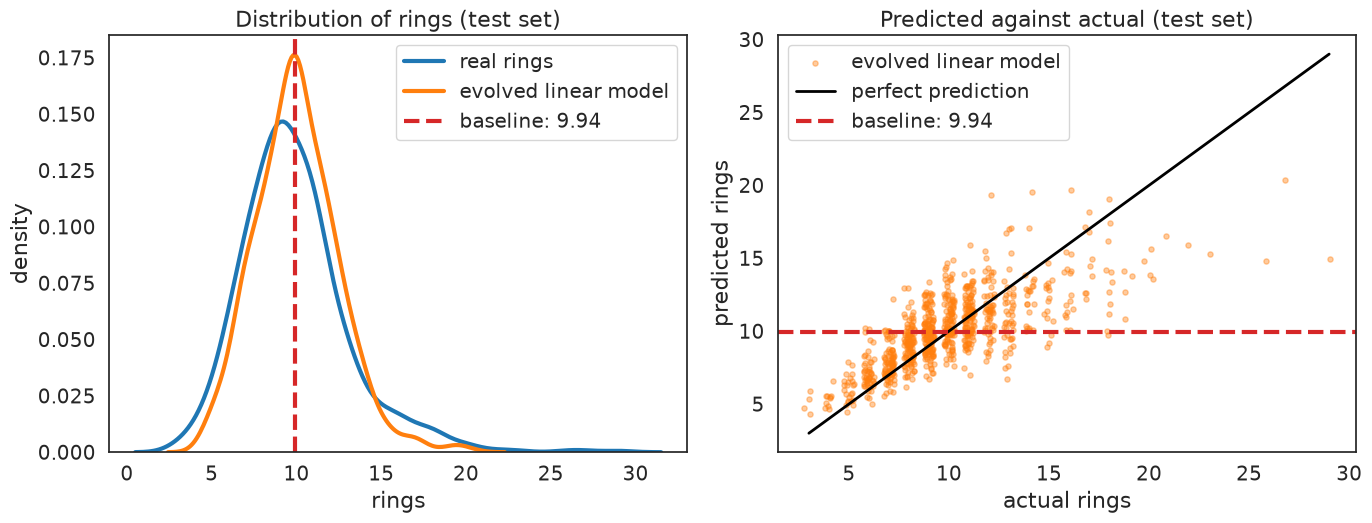

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

def test_evaluate(name, fit_predict):
    """Refit on the whole development part (standardized with its own mean and sd) and score once on the test set."""
    scaler = StandardScaler().fit(X)
    y = test["rings"].to_numpy()
    pred = fit_predict(scaler.transform(X), rings, scaler.transform(test.select(FEATURES).to_numpy()))
    print(f"{name:10s} test RMSE {root_mean_squared_error(y, pred):.3f}   MAE {mean_absolute_error(y, pred):.3f}   R² {r2_score(y, pred):.3f}")
    return pred


def plot_test(pred, name):
    """Left: distribution of the real rings, of the predictions and of the baseline. Right: predicted against actual."""
    y_test, base = test["rings"].to_numpy(), rings.mean()
    jitter = np.random.default_rng(SEED).uniform(-0.25, 0.25, len(y_test))  # rings are integers: spread the dots sideways
    with sns.axes_style("white"), sns.plotting_context("notebook", font_scale=1.3):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
        sns.kdeplot(y_test, ax=ax1, lw=3, color="C0", label="real rings")
        sns.kdeplot(pred, ax=ax1, lw=3, color="C1", label=name)
        ax1.axvline(base, color="C3", lw=3, ls="--", label=f"baseline: {base:.2f}")
        ax1.set(title="Distribution of rings (test set)", xlabel="rings", ylabel="density")
        ax1.legend()
        ax2.scatter(y_test + jitter, pred, s=14, alpha=0.4, color="C1", label=name)
        ax2.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="k", lw=2, label="perfect prediction")
        ax2.axhline(base, color="C3", lw=3, ls="--", label=f"baseline: {base:.2f}")
        ax2.set(title="Predicted against actual (test set)", xlabel="actual rings", ylabel="predicted rings")
        ax2.legend()
        plt.tight_layout()
        plt.show()


test_evaluate("baseline", lambda X_tr, y_tr, X_va: np.full(len(X_va), y_tr.mean()))
final = evolve
pred = test_evaluate("evolved", final)
plot_test(pred, "evolved linear model")

# validation scores of the chosen model and its test predictions, for the comparison in evaluation.ipynb
val = cross_validate(final, verbose=False)
Path("results").mkdir(exist_ok=True)
np.savez("results/evolutionaries.npz", val_rmse=val[:, 0], baseline_rmse=baseline[:, 0], test_y=test["rings"].to_numpy(), test_pred=pred)